# Faster R-CNN on MNIST

Lab 2 - PyTorch computer vision on GPU.

Status: setup and model training completed in Kaggle; validation results verified. Test evaluation remains pending.


## 1. Kaggle environment and reproducibility

Attach the professor's [MNIST dataset](https://www.kaggle.com/datasets/hojjatk/mnist-dataset) and enable a GPU in Kaggle. Run the cells in order. No package upgrades are needed before checking the installed environment.

These setup cells are shared across all five notebooks. Seed 42 and the same official training indices define the common partitions. Training and evaluation run only in Kaggle.


In [2]:
from pathlib import Path
import gzip
import hashlib
import importlib.metadata
import json
import platform
import random
import struct
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchvision
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True

assert torch.cuda.is_available(), 'Enable a GPU in Kaggle before continuing.'
device = torch.device('cuda:0')
RESULTS_DIR = Path('/kaggle/working/results')
PLOTS_DIR = Path('/kaggle/working/plots')
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

environment = {
    'python': platform.python_version(),
    'gpu': torch.cuda.get_device_name(device),
    'cuda_runtime': torch.version.cuda,
    'seed': SEED,
    'packages': {name: importlib.metadata.version(name) for name in
                 ['torch', 'torchvision', 'numpy', 'pandas', 'scikit-learn', 'matplotlib']},
}
print(json.dumps(environment, indent=2))
(RESULTS_DIR / 'mnist_environment.json').write_text(json.dumps(environment, indent=2))


{
  "python": "3.13.15",
  "gpu": "Tesla T4",
  "cuda_runtime": "12.8",
  "seed": 42,
  "packages": {
    "torch": "2.11.0+cu128",
    "torchvision": "0.26.0+cu128",
    "numpy": "2.1.3",
    "pandas": "2.3.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.0"
  }
}


272

### GPU smoke check

A small synthetic forward/backward pass checks GPU execution. It does not train a lab model or access MNIST. Random seeds are reset afterwards.


In [3]:
smoke_model = nn.Sequential(nn.Flatten(), nn.Linear(28 * 28, 10)).to(device)
smoke_x = torch.rand(8, 1, 28, 28, device=device)
smoke_y = torch.arange(8, device=device)
smoke_loss = nn.CrossEntropyLoss()(smoke_model(smoke_x), smoke_y)
smoke_loss.backward()
assert torch.isfinite(smoke_loss)
assert all(p.grad is not None and torch.isfinite(p.grad).all() for p in smoke_model.parameters())
print('PASS: GPU forward pass, cross-entropy, and finite gradients.')
del smoke_model, smoke_x, smoke_y, smoke_loss
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)


PASS: GPU forward pass, cross-entropy, and finite gradients.


## 2. Locate and validate MNIST

The loader reads the official IDX image and label files, including gzip copies. If Kaggle contains duplicate copies, their decompressed contents must agree. File hashes are saved so the other notebooks can verify they use the same data.


In [4]:
INPUT_DIR = Path('/kaggle/input')
file_names = {
    'train_images': 'train-images-idx3-ubyte',
    'train_labels': 'train-labels-idx1-ubyte',
    'test_images': 't10k-images-idx3-ubyte',
    'test_labels': 't10k-labels-idx1-ubyte',
}

def read_bytes(path):
    return gzip.decompress(path.read_bytes()) if path.suffix == '.gz' else path.read_bytes()

source_paths = {}
source_hashes = {}
for key, name in file_names.items():
    alternatives = {name, name.replace('-idx', '.idx')}
    accepted_names = alternatives | {n + '.gz' for n in alternatives}
    matches = sorted(p for p in INPUT_DIR.rglob('*') if p.is_file() and p.name in accepted_names)
    assert matches, f'Missing {name}. Attach the MNIST dataset specified in the lab.'
    hashes = {hashlib.sha256(read_bytes(p)).hexdigest() for p in matches}
    assert len(hashes) == 1, f'Conflicting copies of {name}: {matches}'
    source_paths[key] = matches[0]
    source_hashes[key] = hashes.pop()
    print(f'{key}: {matches[0]} ({len(matches)} matching copies)')

def read_idx(path):
    raw = read_bytes(path)
    assert len(raw) >= 8, f'Incomplete IDX header: {path}'
    magic, count = struct.unpack('>II', raw[:8])
    if magic == 2051:
        rows, cols = struct.unpack('>II', raw[8:16])
        assert (rows, cols) == (28, 28)
        assert len(raw) == 16 + count * rows * cols
        return np.frombuffer(raw, dtype=np.uint8, offset=16).reshape(count, rows, cols).copy()
    assert magic == 2049, f'Unexpected IDX magic number: {magic}'
    assert len(raw) == 8 + count
    return np.frombuffer(raw, dtype=np.uint8, offset=8).copy()

official_train_images = read_idx(source_paths['train_images'])
official_train_labels = read_idx(source_paths['train_labels'])
official_test_images = read_idx(source_paths['test_images'])
official_test_labels = read_idx(source_paths['test_labels'])
assert official_train_images.shape == (60000, 28, 28)
assert official_test_images.shape == (10000, 28, 28)
assert official_train_labels.shape == (60000,)
assert official_test_labels.shape == (10000,)
for labels in (official_train_labels, official_test_labels):
    assert np.array_equal(np.unique(labels), np.arange(10))
print('Official training images:', official_train_images.shape)
print('Official test images:', official_test_images.shape)
print('Pixel dtype:', official_train_images.dtype)
print('Training pixel range:', official_train_images.min(), official_train_images.max())
print('PASS: IDX sizes, image dimensions, and label ranges.')


train_images: /kaggle/input/datasets/hojjatk/mnist-dataset/train-images-idx3-ubyte/train-images-idx3-ubyte (2 matching copies)
train_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/train-labels-idx1-ubyte/train-labels-idx1-ubyte (2 matching copies)
test_images: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-images-idx3-ubyte/t10k-images-idx3-ubyte (2 matching copies)
test_labels: /kaggle/input/datasets/hojjatk/mnist-dataset/t10k-labels-idx1-ubyte/t10k-labels-idx1-ubyte (2 matching copies)
Official training images: (60000, 28, 28)
Official test images: (10000, 28, 28)
Pixel dtype: uint8
Training pixel range: 0 255
PASS: IDX sizes, image dimensions, and label ranges.


## 3. Shared train, validation, and test partitions

Split the official training set into 54,000 training and 6,000 validation images, stratified by digit. Keep the 10,000 official test images separate. Test labels are used here only for structural checks and partition counts, never for model selection.

The split manifest identifies images by their original index and source partition. Indices from the official train and test files belong to different namespaces. A hash of the manifest allows exact cross-notebook comparison.


In [5]:
train_indices, validation_indices = train_test_split(
    np.arange(len(official_train_labels)),
    test_size=6000,
    random_state=SEED,
    stratify=official_train_labels,
)
train_indices = np.sort(train_indices)
validation_indices = np.sort(validation_indices)
test_indices = np.arange(len(official_test_labels))
assert len(np.intersect1d(train_indices, validation_indices)) == 0
assert np.array_equal(np.sort(np.concatenate([train_indices, validation_indices])), np.arange(60000))

split_manifest = pd.concat([
    pd.DataFrame({'split': 'train', 'source': 'official_train', 'source_index': train_indices}),
    pd.DataFrame({'split': 'validation', 'source': 'official_train', 'source_index': validation_indices}),
    pd.DataFrame({'split': 'test', 'source': 'official_test', 'source_index': test_indices}),
], ignore_index=True)
assert not split_manifest.duplicated(['source', 'source_index']).any()
manifest_text = split_manifest.to_csv(index=False, lineterminator='\n')
split_hash = hashlib.sha256(manifest_text.encode()).hexdigest()
(RESULTS_DIR / 'mnist_split_manifest.csv').write_text(manifest_text)

split_labels = {
    'train': official_train_labels[train_indices],
    'validation': official_train_labels[validation_indices],
    'test': official_test_labels,
}
class_counts = pd.DataFrame({name: np.bincount(labels, minlength=10) for name, labels in split_labels.items()})
class_counts.index.name = 'digit'
assert (class_counts > 0).all().all()
display(class_counts)
class_counts.to_csv(RESULTS_DIR / 'mnist_split_class_counts.csv')
print('Partition sizes:', {name: len(labels) for name, labels in split_labels.items()})
print('Split SHA256:', split_hash)
print('PASS: disjoint source indices, full coverage, and all ten classes in each partition.')


,train,validation,test
digit,,,
0,5331,592,980
1,6068,674,1135
2,5362,596,1032
3,5518,613,1010
4,5258,584,982
5,4879,542,892
6,5326,592,958
7,5638,627,1028
8,5266,585,974


Partition sizes: {'train': 54000, 'validation': 6000, 'test': 10000}
Split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: disjoint source indices, full coverage, and all ten classes in each partition.


### Training examples and class distribution

Inspect training images only. No balancing is planned unless the observed data justify it; the lab does not request an oversampling experiment.


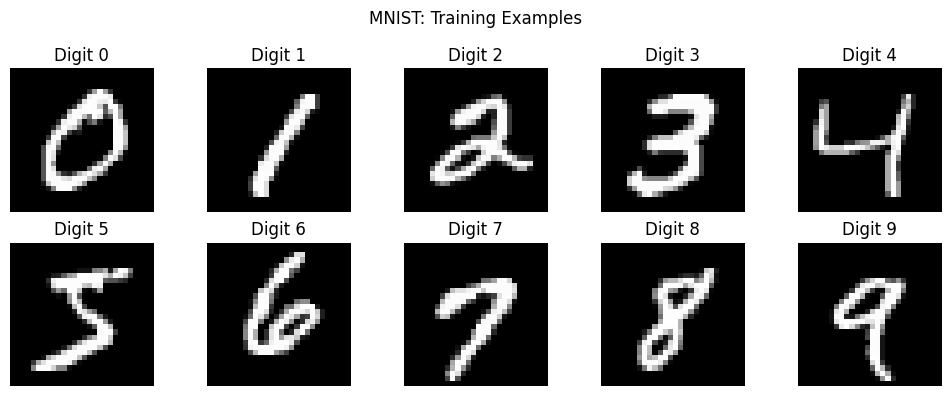

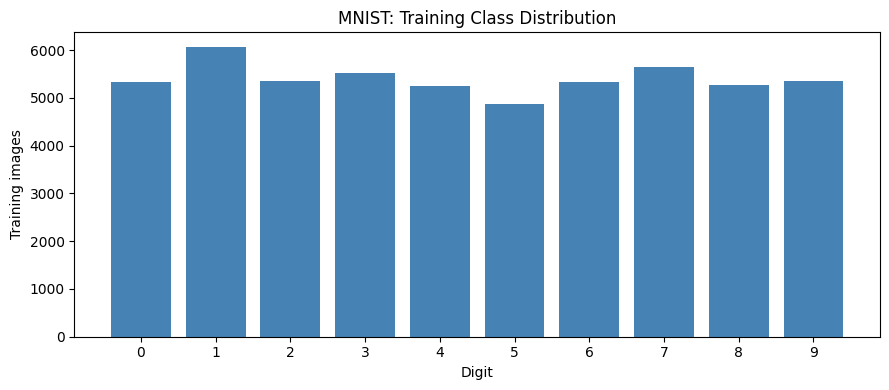

In [6]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for digit, ax in enumerate(axes.flat):
    index = train_indices[np.flatnonzero(official_train_labels[train_indices] == digit)[0]]
    ax.imshow(official_train_images[index], cmap='gray', vmin=0, vmax=255)
    ax.set_title(f'Digit {digit}')
    ax.axis('off')
fig.suptitle('MNIST: Training Examples')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_examples.png', dpi=160, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(class_counts.index, class_counts['train'], color='steelblue')
ax.set(xticks=range(10), xlabel='Digit', ylabel='Training images', title='MNIST: Training Class Distribution')
fig.tight_layout()
fig.savefig(PLOTS_DIR / 'mnist_training_class_distribution.png', dpi=160, bbox_inches='tight')
plt.show()


## 4. Shared input and evaluation conventions

The CNN and scratch ViT start with grayscale pixels divided by 255. This fixed conversion does not estimate statistics from validation or test data. VGG16 and AlexNet will use three channels, resizing, and the normalization specified by their pretrained weights. Faster R-CNN will use its documented detection transforms. The raw images and split indices remain available for these model-specific steps.

Accuracy measures correct digit predictions. Macro-F1 gives equal weight to all ten digits. Classification loss is unweighted cross-entropy; Faster R-CNN detection loss will be reported separately because it includes classification and box-related terms. A missing detection counts as an incorrect prediction, never a discarded example.

Training time excludes data and weight downloads, includes validation within the training loop, and uses CUDA synchronization before and after timing. Record actual epochs, batch size, and GPU for each model. Model and checkpoint selection uses validation only; test evaluation is deferred until all configurations are frozen.


In [7]:
X_train = torch.from_numpy(official_train_images[train_indices]).unsqueeze(1).float().div(255)
y_train = torch.from_numpy(official_train_labels[train_indices].astype(np.int64))
X_validation = torch.from_numpy(official_train_images[validation_indices]).unsqueeze(1).float().div(255)
y_validation = torch.from_numpy(official_train_labels[validation_indices].astype(np.int64))
assert X_train.shape == (54000, 1, 28, 28)
assert X_validation.shape == (6000, 1, 28, 28)
assert y_train.dtype == torch.int64
assert torch.isfinite(X_train).all() and torch.isfinite(X_validation).all()
assert 0 <= X_train.min() <= X_train.max() <= 1

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)

loader_generator = torch.Generator().manual_seed(SEED)
train_loader = DataLoader(TensorDataset(X_train, y_train), batch_size=64,
                          shuffle=True, generator=loader_generator, num_workers=0,
                          worker_init_fn=seed_worker, pin_memory=True)
validation_loader = DataLoader(TensorDataset(X_validation, y_validation), batch_size=64,
                               shuffle=False, num_workers=0, pin_memory=True)

def classification_metrics(y_true, y_pred):
    return {
        'accuracy': float(accuracy_score(y_true, y_pred)),
        'macro_f1': float(f1_score(y_true, y_pred, labels=np.arange(10), average='macro', zero_division=0)),
    }

def gpu_time():
    torch.cuda.synchronize(device)
    return time.perf_counter()

print('Training tensors:', X_train.shape, y_train.shape)
print('Validation tensors:', X_validation.shape, y_validation.shape)
print('Input dtype:', X_train.dtype, '| Target dtype:', y_train.dtype)
print('Batches per training epoch:', len(train_loader))
print('PASS: tensors and data loaders ready. No test predictions computed.')


Training tensors: torch.Size([54000, 1, 28, 28]) torch.Size([54000])
Validation tensors: torch.Size([6000, 1, 28, 28]) torch.Size([6000])
Input dtype: torch.float32 | Target dtype: torch.int64
Batches per training epoch: 844
PASS: tensors and data loaders ready. No test predictions computed.


### Faster R-CNN adaptation and setup export

Proposed adaptation: one digit per image, with a derived full-image bounding box. This is not a localization annotation supplied by MNIST. Detector label 0 is background; digit labels 0-9 map to 1-10. Keep the complete detector and use the highest-scoring detection for image classification. Fix its score threshold using validation before the final test. If there is no detection, use an incorrect-prediction sentinel rather than dropping the image.

This is an implementation choice because the assignment does not specify how to adapt MNIST to detection. A clarification from the professor takes precedence. Detector construction and visual checks of these targets belong to Issue 3.


In [8]:
setup_config = {
    'dataset': 'hojjatk/mnist-dataset',
    'seed': SEED,
    'source_sha256': source_hashes,
    'split_sha256': split_hash,
    'partition_sizes': {name: len(labels) for name, labels in split_labels.items()},
    'split_policy': 'Stratified holdout from official train; official test kept separate',
    'cnn_vit_input': 'float32 grayscale pixels / 255; NCHW',
    'class_labels': list(range(10)),
    'metrics': ['accuracy', 'macro_f1', 'loss', 'training_seconds'],
    'selection_data': 'validation only',
    'timing': 'CUDA synchronized; includes per-epoch validation; excludes downloads',
    'faster_rcnn': {
        'box_policy': 'one derived full-image box per image',
        'background_label': 0,
        'digit_to_detector_label': 'digit + 1',
        'image_prediction': 'highest-scoring detection; no detection counts as incorrect',
        'score_threshold': 'to be fixed using validation in Issue 3',
        'loss_note': 'detection loss is not directly comparable to classifier cross-entropy',
    },
    'test_predictions_computed': False,
}
(RESULTS_DIR / 'mnist_setup_config.json').write_text(json.dumps(setup_config, indent=2))
print('Saved setup configuration:', RESULTS_DIR / 'mnist_setup_config.json')
print('PASS: Issue 1 setup cells completed. Review outputs before closing the issue.')


Saved setup configuration: /kaggle/working/results/mnist_setup_config.json
PASS: Issue 1 setup cells completed. Review outputs before closing the issue.


## 5. Model experiment

The following cells implement the detection adaptation, train Faster R-CNN on two GPUs, and verify its selected validation predictions. The formal comparison with the CNN follows in Issue 4.


In [9]:
from torch.utils.data import Dataset


class MNISTDetectionDataset(Dataset):
    def __init__(self, images, labels, indices):
        self.images = images
        self.labels = labels
        self.indices = np.asarray(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        source_index = int(self.indices[position])

        image = torch.from_numpy(
            self.images[source_index].copy()
        ).unsqueeze(0).float().div(255)

        image = image.repeat(3, 1, 1)
        height, width = image.shape[-2:]

        target = {
            "boxes": torch.tensor(
                [[0.0, 0.0, float(width), float(height)]],
                dtype=torch.float32,
            ),
            "labels": torch.tensor(
                [int(self.labels[source_index]) + 1],
                dtype=torch.int64,
            ),
            "image_id": torch.tensor([source_index], dtype=torch.int64),
            "area": torch.tensor(
                [float(width * height)],
                dtype=torch.float32,
            ),
            "iscrowd": torch.zeros(1, dtype=torch.int64),
        }

        return image, target


def detection_collate(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)


detection_train_dataset = MNISTDetectionDataset(
    official_train_images,
    official_train_labels,
    train_indices,
)

detection_validation_dataset = MNISTDetectionDataset(
    official_train_images,
    official_train_labels,
    validation_indices,
)

sample_image, sample_target = detection_train_dataset[0]

assert sample_image.shape == (3, 28, 28)
assert sample_image.dtype == torch.float32
assert sample_target["boxes"].shape == (1, 4)
assert sample_target["labels"].dtype == torch.int64
assert 1 <= sample_target["labels"].item() <= 10
assert torch.isfinite(sample_image).all()

print("Training images:", len(detection_train_dataset))
print("Validation images:", len(detection_validation_dataset))
print("Sample image shape:", tuple(sample_image.shape))
print("Bounding box:", sample_target["boxes"].tolist())
print("Detector label:", sample_target["labels"].item())
print("Original digit:", sample_target["labels"].item() - 1)
print("PASS: detection dataset and target format.")
print("Test set remains unused for model evaluation.")

Training images: 54000
Validation images: 6000
Sample image shape: (3, 28, 28)
Bounding box: [[0.0, 0.0, 28.0, 28.0]]
Detector label: 6
Original digit: 5
PASS: detection dataset and target format.
Test set remains unused for model evaluation.


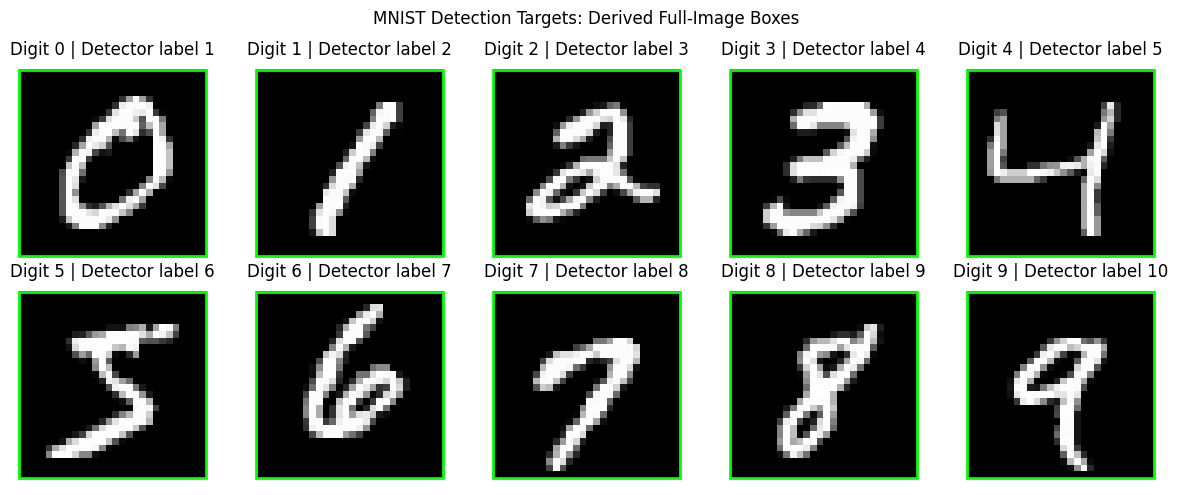

PASS: all ten digits map to detector labels 1–10.


In [10]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

training_digits = official_train_labels[train_indices]

for digit, ax in enumerate(axes.flat):
    position = int(np.flatnonzero(training_digits == digit)[0])
    image, target = detection_train_dataset[position]

    x1, y1, x2, y2 = target["boxes"][0].tolist()
    detector_label = int(target["labels"][0])

    assert detector_label == digit + 1

    ax.imshow(
        image.permute(1, 2, 0).numpy(),
        extent=(0, 28, 28, 0),
        interpolation="nearest",
    )
    ax.add_patch(Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="lime",
        linewidth=2,
    ))
    ax.set(
        title=f"Digit {digit} | Detector label {detector_label}",
        xlim=(-1, 29),
        ylim=(29, -1),
    )
    ax.axis("off")

fig.suptitle("MNIST Detection Targets: Derived Full-Image Boxes")
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "faster_rcnn_training_targets.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("PASS: all ten digits map to detector labels 1–10.")

In [11]:
faster_rcnn_config = {
    "seed": SEED,
    "backbone": "custom_cnn",
    "pretrained": False,
    "backbone_channels": [32, 64],
    "image_size": 28,
    "num_classes": 11,
    "anchor_sizes": [16, 28, 40],
    "anchor_aspect_ratios": [0.5, 1.0, 2.0],
    "roi_output_size": 7,
    "head_hidden_units": 128,
    "rpn_pre_nms_top_n": 200,
    "rpn_post_nms_top_n": 50,
    "rpn_batch_size_per_image": 128,
    "box_batch_size_per_image": 64,
    "box_score_thresh": 0.0,
    "box_nms_thresh": 0.5,
    "detections_per_image": 1,
    "optimizer": "Adam",
    "learning_rate": 0.001,
    "batch_size": 32,
    "max_epochs": 10,
    "checkpoint_selection": "highest validation macro-F1",
    "checkpoint_tie_break": "earliest epoch",
    "gpus_used": 1,
}

assert len(detection_train_dataset) == 54000
assert len(detection_validation_dataset) == 6000

print(json.dumps(faster_rcnn_config, indent=2))
print("Detector classes: background + ten digits.")
print("Input: three identical grayscale channels, pixels in [0, 1].")
print("No pretrained weights or ImageNet normalization.")
print("Prediction: highest-scoring detection; missing detection = incorrect.")
print("Test set remains unevaluated.")

{
  "seed": 42,
  "backbone": "custom_cnn",
  "pretrained": false,
  "backbone_channels": [
    32,
    64
  ],
  "image_size": 28,
  "num_classes": 11,
  "anchor_sizes": [
    16,
    28,
    40
  ],
  "anchor_aspect_ratios": [
    0.5,
    1.0,
    2.0
  ],
  "roi_output_size": 7,
  "head_hidden_units": 128,
  "rpn_pre_nms_top_n": 200,
  "rpn_post_nms_top_n": 50,
  "rpn_batch_size_per_image": 128,
  "box_batch_size_per_image": 64,
  "box_score_thresh": 0.0,
  "box_nms_thresh": 0.5,
  "detections_per_image": 1,
  "optimizer": "Adam",
  "learning_rate": 0.001,
  "batch_size": 32,
  "max_epochs": 10,
  "checkpoint_selection": "highest validation macro-F1",
  "checkpoint_tie_break": "earliest epoch",
  "gpus_used": 1
}
Detector classes: background + ten digits.
Input: three identical grayscale channels, pixels in [0, 1].
No pretrained weights or ImageNet normalization.
Prediction: highest-scoring detection; missing detection = incorrect.
Test set remains unevaluated.


In [12]:
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import (
    TwoMLPHead,
    FastRCNNPredictor,
)
from torchvision.ops import MultiScaleRoIAlign

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

cfg = faster_rcnn_config
c1, c2 = cfg["backbone_channels"]

backbone = nn.Sequential(
    nn.Conv2d(3, c1, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(c1, c2, kernel_size=3, padding=1),
    nn.ReLU(),
    nn.MaxPool2d(2),
)
backbone.out_channels = c2

anchor_generator = AnchorGenerator(
    sizes=(tuple(cfg["anchor_sizes"]),),
    aspect_ratios=(tuple(cfg["anchor_aspect_ratios"]),),
)

roi_pool = MultiScaleRoIAlign(
    featmap_names=["0"],
    output_size=cfg["roi_output_size"],
    sampling_ratio=2,
)

box_head = TwoMLPHead(
    c2 * cfg["roi_output_size"] ** 2,
    cfg["head_hidden_units"],
)

box_predictor = FastRCNNPredictor(
    cfg["head_hidden_units"],
    cfg["num_classes"],
)

faster_rcnn_model = FasterRCNN(
    backbone=backbone,
    num_classes=None,
    min_size=cfg["image_size"],
    max_size=cfg["image_size"],
    image_mean=[0.0, 0.0, 0.0],
    image_std=[1.0, 1.0, 1.0],
    rpn_anchor_generator=anchor_generator,
    box_roi_pool=roi_pool,
    box_head=box_head,
    box_predictor=box_predictor,
    rpn_pre_nms_top_n_train=cfg["rpn_pre_nms_top_n"],
    rpn_pre_nms_top_n_test=cfg["rpn_pre_nms_top_n"],
    rpn_post_nms_top_n_train=cfg["rpn_post_nms_top_n"],
    rpn_post_nms_top_n_test=cfg["rpn_post_nms_top_n"],
    rpn_batch_size_per_image=cfg["rpn_batch_size_per_image"],
    box_batch_size_per_image=cfg["box_batch_size_per_image"],
    box_score_thresh=cfg["box_score_thresh"],
    box_nms_thresh=cfg["box_nms_thresh"],
    box_detections_per_img=cfg["detections_per_image"],
).to(device)

sample_batch = [detection_train_dataset[i] for i in range(2)]
sample_images, sample_targets = detection_collate(sample_batch)
sample_images = [image.to(device) for image in sample_images]
sample_targets = [
    {key: value.to(device) for key, value in target.items()}
    for target in sample_targets
]

with torch.random.fork_rng(devices=[device.index]):
    faster_rcnn_model.train()
    with torch.no_grad():
        sample_losses = faster_rcnn_model(sample_images, sample_targets)

    expected_losses = {
        "loss_classifier",
        "loss_box_reg",
        "loss_objectness",
        "loss_rpn_box_reg",
    }
    assert set(sample_losses) == expected_losses
    assert all(torch.isfinite(value).all() for value in sample_losses.values())

    faster_rcnn_model.eval()
    with torch.no_grad():
        sample_predictions = faster_rcnn_model(sample_images)

assert len(sample_predictions) == len(sample_images)

for prediction in sample_predictions:
    count = len(prediction["labels"])
    assert prediction["boxes"].shape == (count, 4)
    assert prediction["scores"].shape == (count,)
    assert count <= cfg["detections_per_image"]
    assert torch.isfinite(prediction["boxes"]).all()
    assert torch.isfinite(prediction["scores"]).all()
    assert ((prediction["labels"] >= 1) & (prediction["labels"] <= 10)).all()

faster_rcnn_model.train()

print("Backbone:", backbone)
print(
    "Trainable parameters:",
    sum(p.numel() for p in faster_rcnn_model.parameters() if p.requires_grad),
)
print("Device:", next(faster_rcnn_model.parameters()).device)
print("Training loss components:")
for name, value in sample_losses.items():
    print(f"  {name}: {value.item():.6f}")

print(
    "Detections per sample:",
    [len(prediction["labels"]) for prediction in sample_predictions],
)
print("PASS: finite detection losses and valid inference outputs.")
print("No optimizer updates performed; test set remains unevaluated.")

Backbone: Sequential(
  (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
)
Trainable parameters: 484388
Device: cuda:0
Training loss components:
  loss_classifier: 2.418048
  loss_box_reg: 0.866275
  loss_objectness: 0.693020
  loss_rpn_box_reg: 0.001436
Detections per sample: [1, 1]
PASS: finite detection losses and valid inference outputs.
No optimizer updates performed; test set remains unevaluated.


In [13]:
detection_generator = torch.Generator().manual_seed(SEED)

detection_train_loader = DataLoader(
    detection_train_dataset,
    batch_size=faster_rcnn_config["batch_size"],
    shuffle=True,
    generator=detection_generator,
    collate_fn=detection_collate,
    num_workers=0,
    pin_memory=True,
)

detection_train_eval_loader = DataLoader(
    detection_train_dataset,
    batch_size=faster_rcnn_config["batch_size"],
    shuffle=False,
    collate_fn=detection_collate,
    num_workers=0,
    pin_memory=True,
)

detection_validation_loader = DataLoader(
    detection_validation_dataset,
    batch_size=faster_rcnn_config["batch_size"],
    shuffle=False,
    collate_fn=detection_collate,
    num_workers=0,
    pin_memory=True,
)

faster_rcnn_optimizer = torch.optim.Adam(
    faster_rcnn_model.parameters(),
    lr=faster_rcnn_config["learning_rate"],
)

assert len(detection_train_loader.dataset) == 54000
assert len(detection_validation_loader.dataset) == 6000

print("Batch size:", faster_rcnn_config["batch_size"])
print("Training batches per epoch:", len(detection_train_loader))
print("Training evaluation batches:", len(detection_train_eval_loader))
print("Validation batches:", len(detection_validation_loader))
print("Optimizer: Adam")
print("Learning rate:", faster_rcnn_config["learning_rate"])
print("PASS: detection data loaders and optimizer ready.")

Batch size: 32
Training batches per epoch: 1688
Training evaluation batches: 1688
Validation batches: 188
Optimizer: Adam
Learning rate: 0.001
PASS: detection data loaders and optimizer ready.


In [14]:
def evaluate_faster_rcnn(model, loader):
    original_modes = [(module, module.training) for module in model.modules()]

    loss_totals = {}
    total_images = 0
    true_digits = []
    predicted_digits = []
    missing_detections = 0

    try:
        with torch.random.fork_rng(devices=[device.index]):
            torch.manual_seed(SEED)
            torch.cuda.manual_seed_all(SEED)

            with torch.no_grad():
                for images, targets in loader:
                    images = [
                        image.to(device, non_blocking=True)
                        for image in images
                    ]
                    targets = [
                        {
                            key: value.to(device, non_blocking=True)
                            for key, value in target.items()
                        }
                        for target in targets
                    ]

                    model.eval()
                    predictions = model(images)
                    assert len(predictions) == len(targets)

                    for target, prediction in zip(targets, predictions):
                        true_digits.append(int(target["labels"][0].item()) - 1)

                        if prediction["scores"].numel() == 0:
                            predicted_digits.append(-1)
                            missing_detections += 1
                        else:
                            best = prediction["scores"].argmax()
                            digit = int(prediction["labels"][best].item()) - 1
                            assert 0 <= digit <= 9
                            predicted_digits.append(digit)

                    model.train()

                    # Prevent running-statistic updates and disable dropout.
                    for module in model.modules():
                        if isinstance(
                            module,
                            (
                                nn.modules.batchnorm._BatchNorm,
                                nn.Dropout,
                                nn.Dropout2d,
                                nn.Dropout3d,
                            ),
                        ):
                            module.eval()

                    losses = model(images, targets)
                    batch_size = len(images)

                    for name, value in losses.items():
                        if not torch.isfinite(value).all():
                            raise RuntimeError(f"Non-finite {name}.")

                        loss_totals[name] = (
                            loss_totals.get(name, 0.0)
                            + value.item() * batch_size
                        )

                    total_images += batch_size

    finally:
        for module, training_mode in original_modes:
            module.training = training_mode

    assert total_images == len(loader.dataset)
    assert len(true_digits) == len(predicted_digits) == total_images

    mean_losses = {
        name: total / total_images
        for name, total in loss_totals.items()
    }

    y_true = np.asarray(true_digits, dtype=np.int64)
    y_pred = np.asarray(predicted_digits, dtype=np.int64)

    metrics = {
        "loss": sum(mean_losses.values()),
        **mean_losses,
        **classification_metrics(y_true, y_pred),
        "missing_detections": missing_detections,
    }

    return metrics, y_true, y_pred


print("Evaluation function ready.")
print("Accuracy and macro-F1: inference predictions over all images.")
print("Missing detections: counted as incorrect predictions.")
print("Detection loss: image-weighted average of batch losses.")
print("Loss sampling uses a fixed seed without advancing training RNG state.")
print("No optimizer updates or test evaluation performed.")

Evaluation function ready.
Accuracy and macro-F1: inference predictions over all images.
Missing detections: counted as incorrect predictions.
Detection loss: image-weighted average of batch losses.
Loss sampling uses a fixed seed without advancing training RNG state.
No optimizer updates or test evaluation performed.


In [15]:
benchmark_samples = [
    detection_train_dataset[i]
    for i in range(faster_rcnn_config["batch_size"])
]
benchmark_images, benchmark_targets = detection_collate(benchmark_samples)


def benchmark_training_step():
    images = [image.to(device) for image in benchmark_images]
    targets = [
        {key: value.to(device) for key, value in target.items()}
        for target in benchmark_targets
    ]

    faster_rcnn_optimizer.zero_grad(set_to_none=True)
    losses = faster_rcnn_model(images, targets)
    loss = sum(losses.values())

    assert torch.isfinite(loss)
    loss.backward()


original_mode = faster_rcnn_model.training

try:
    with torch.random.fork_rng(
        devices=list(range(torch.cuda.device_count()))
    ):
        faster_rcnn_model.train()

        for _ in range(2):
            benchmark_training_step()

        benchmark_start = gpu_time()

        for _ in range(5):
            benchmark_training_step()

        seconds_per_training_batch = (
            gpu_time() - benchmark_start
        ) / 5

        benchmark_eval_loader = DataLoader(
            torch.utils.data.Subset(
                detection_train_dataset,
                range(96),
            ),
            batch_size=faster_rcnn_config["batch_size"],
            shuffle=False,
            collate_fn=detection_collate,
            num_workers=0,
            pin_memory=True,
        )

        benchmark_start = gpu_time()
        benchmark_metrics, _, _ = evaluate_faster_rcnn(
            faster_rcnn_model,
            benchmark_eval_loader,
        )
        seconds_per_eval_image = (gpu_time() - benchmark_start) / 96

finally:
    faster_rcnn_optimizer.zero_grad(set_to_none=True)
    faster_rcnn_model.train(original_mode)

estimated_epoch_seconds = (
    seconds_per_training_batch * len(detection_train_loader)
    + seconds_per_eval_image
    * (
        len(detection_train_dataset)
        + len(detection_validation_dataset)
    )
)

print(f"Training computation per batch: {seconds_per_training_batch:.4f}s")
print(f"Evaluation time per image: {seconds_per_eval_image:.5f}s")
print(f"Estimated epoch time: {estimated_epoch_seconds / 60:.2f} minutes")
print(
    "Estimated 10-epoch time:",
    f"{estimated_epoch_seconds * faster_rcnn_config['max_epochs'] / 60:.2f} minutes",
)
print("Rough estimate: excludes optimizer-step and full training-loader overhead.")
print("Detection counts and timing may change as the model learns.")
print("PASS: benchmark completed without optimizer updates.")
print("Test set remains unevaluated.")

Training computation per batch: 0.1444s
Evaluation time per image: 0.00745s
Estimated epoch time: 11.51 minutes
Estimated 10-epoch time: 115.09 minutes
Rough estimate: excludes optimizer-step and full training-loader overhead.
Detection counts and timing may change as the model learns.
PASS: benchmark completed without optimizer updates.
Test set remains unevaluated.


In [16]:
import torch.distributed as dist

gpu_count = torch.cuda.device_count()

print("Visible GPUs:", gpu_count)
for index in range(gpu_count):
    properties = torch.cuda.get_device_properties(index)
    print(
        f"GPU {index}: {properties.name} | "
        f"Memory: {properties.total_memory / 1024**3:.1f} GiB"
    )

print("Distributed support:", dist.is_available())
print("NCCL support:", dist.is_nccl_available())

assert gpu_count >= 2, "Enable the two-T4 accelerator in Kaggle."
assert dist.is_available()
assert dist.is_nccl_available()

ddp_plan = {
    "world_size": 2,
    "global_batch_size": faster_rcnn_config["batch_size"],
    "batch_size_per_gpu": faster_rcnn_config["batch_size"] // 2,
    "max_epochs": faster_rcnn_config["max_epochs"],
    "learning_rate": faster_rcnn_config["learning_rate"],
}

assert ddp_plan["global_batch_size"] % ddp_plan["world_size"] == 0

print(json.dumps(ddp_plan, indent=2))
print("PASS: prerequisites available; two-process communication not yet tested.")
print("No model updates performed.")

Visible GPUs: 2
GPU 0: Tesla T4 | Memory: 14.6 GiB
GPU 1: Tesla T4 | Memory: 14.6 GiB
Distributed support: True
NCCL support: True
{
  "world_size": 2,
  "global_batch_size": 32,
  "batch_size_per_gpu": 16,
  "max_epochs": 10,
  "learning_rate": 0.001
}
PASS: prerequisites available; two-process communication not yet tested.
No model updates performed.


In [17]:
import subprocess
import sys
import textwrap

ddp_probe_path = Path("/kaggle/working/ddp_probe.py")

ddp_probe_path.write_text(
    textwrap.dedent("""
        import os
        from datetime import timedelta

        import torch
        import torch.distributed as dist

        local_rank = int(os.environ["LOCAL_RANK"])
        torch.cuda.set_device(local_rank)

        dist.init_process_group(
            backend="nccl",
            timeout=timedelta(seconds=60),
        )

        try:
            rank = dist.get_rank()
            world_size = dist.get_world_size()
            assert world_size == 2

            value = torch.tensor(
                [float(rank + 1)],
                device=f"cuda:{local_rank}",
            )
            dist.all_reduce(value, op=dist.ReduceOp.SUM)
            torch.cuda.synchronize(local_rank)

            assert value.item() == 3.0

            print(
                f"Rank {rank} | GPU {local_rank}: "
                f"{torch.cuda.get_device_name(local_rank)} | "
                f"All-reduce result: {value.item()}",
                flush=True,
            )

            dist.barrier()
            if rank == 0:
                print("PASS: two-GPU NCCL communication.", flush=True)
        finally:
            dist.destroy_process_group()
    """).strip() + "\n",
    encoding="utf-8",
)

probe_result = subprocess.run(
    [
        sys.executable,
        "-m", "torch.distributed.run",
        "--standalone",
        "--nnodes=1",
        "--nproc-per-node=2",
        str(ddp_probe_path),
    ],
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
)

print(probe_result.stdout)
assert probe_result.returncode == 0, "DDP communication check failed."
print("Notebook model weights remain unchanged.")


*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************
Rank 0 | GPU 0: Tesla T4 | All-reduce result: 3.0Rank 1 | GPU 1: Tesla T4 | All-reduce result: 3.0

/usr/local/lib/python3.13/dist-packages/torch/distributed/c10d_logger.py:83: UserWarning: barrier(): using the device under current context. You can specify `device_id` in `init_process_group` to mute this warning.
  return func(*args, **kwargs)
PASS: two-GPU NCCL communication.

Notebook model weights remain unchanged.


In [18]:
ddp_work_dir = Path("/kaggle/working/faster_rcnn_ddp")
ddp_work_dir.mkdir(parents=True, exist_ok=True)

assert len(faster_rcnn_optimizer.state) == 0, (
    "The optimizer already contains training state. "
    "Do not export these weights as an untrained initialization."
)

assert len(train_indices) == 54000
assert len(validation_indices) == 6000
assert len(np.intersect1d(train_indices, validation_indices)) == 0

np.save(
    ddp_work_dir / "official_train_images.npy",
    official_train_images,
)
np.save(
    ddp_work_dir / "official_train_labels.npy",
    official_train_labels,
)
np.save(ddp_work_dir / "train_indices.npy", train_indices)
np.save(ddp_work_dir / "validation_indices.npy", validation_indices)

initial_state = {
    name: tensor.detach().cpu().clone()
    for name, tensor in faster_rcnn_model.state_dict().items()
}
torch.save(initial_state, ddp_work_dir / "initial_weights.pt")

ddp_config = {
    **faster_rcnn_config,
    "gpus_used": ddp_plan["world_size"],
    "global_batch_size": ddp_plan["global_batch_size"],
    "batch_size_per_gpu": ddp_plan["batch_size_per_gpu"],
    "split_sha256": split_hash,
    "source_sha256": source_hashes,
    "environment": environment,
}

(ddp_work_dir / "config.json").write_text(
    json.dumps(ddp_config, indent=2),
    encoding="utf-8",
)

print("Worker input directory:", ddp_work_dir)
print("Training samples:", len(train_indices))
print("Validation samples:", len(validation_indices))
print("Global batch size:", ddp_config["global_batch_size"])
print("Batch size per GPU:", ddp_config["batch_size_per_gpu"])
print("Initial parameter count:", sum(
    p.numel() for p in faster_rcnn_model.parameters()
))
print("Split SHA256:", split_hash)
print("PASS: worker inputs and initial weights saved.")
print("No training performed; no test data exported.")

Worker input directory: /kaggle/working/faster_rcnn_ddp
Training samples: 54000
Validation samples: 6000
Global batch size: 32
Batch size per GPU: 16
Initial parameter count: 484388
Split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: worker inputs and initial weights saved.
No training performed; no test data exported.


In [19]:
%%writefile /kaggle/working/faster_rcnn_ddp/worker.py
import argparse
import json
import os
import random
import time
from datetime import timedelta
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.distributed as dist
from torch import nn
from torch.nn.parallel import DistributedDataParallel as DDP
from torch.utils.data import DataLoader, Dataset, DistributedSampler
from torchvision.models.detection import FasterRCNN
from torchvision.models.detection.anchor_utils import AnchorGenerator
from torchvision.models.detection.faster_rcnn import (
    FastRCNNPredictor,
    TwoMLPHead,
)
from torchvision.ops import MultiScaleRoIAlign


ROOT = Path(__file__).resolve().parent
LOSS_NAMES = [
    "loss_classifier",
    "loss_box_reg",
    "loss_objectness",
    "loss_rpn_box_reg",
]


class DetectionDataset(Dataset):
    def __init__(self, images, labels, indices):
        self.images = images
        self.labels = labels
        self.indices = indices

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, position):
        index = int(self.indices[position])
        image = torch.from_numpy(
            self.images[index].copy()
        ).unsqueeze(0).float().div(255).repeat(3, 1, 1)

        target = {
            "boxes": torch.tensor(
                [[0.0, 0.0, 28.0, 28.0]], dtype=torch.float32
            ),
            "labels": torch.tensor(
                [int(self.labels[index]) + 1], dtype=torch.int64
            ),
        }
        return image, target


def collate(batch):
    images, targets = zip(*batch)
    return list(images), list(targets)


def build_model(cfg):
    c1, c2 = cfg["backbone_channels"]
    backbone = nn.Sequential(
        nn.Conv2d(3, c1, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(c1, c2, 3, padding=1),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )
    backbone.out_channels = c2

    return FasterRCNN(
        backbone,
        num_classes=None,
        min_size=cfg["image_size"],
        max_size=cfg["image_size"],
        image_mean=[0.0, 0.0, 0.0],
        image_std=[1.0, 1.0, 1.0],
        rpn_anchor_generator=AnchorGenerator(
            sizes=(tuple(cfg["anchor_sizes"]),),
            aspect_ratios=(tuple(cfg["anchor_aspect_ratios"]),),
        ),
        box_roi_pool=MultiScaleRoIAlign(
            featmap_names=["0"],
            output_size=cfg["roi_output_size"],
            sampling_ratio=2,
        ),
        box_head=TwoMLPHead(
            c2 * cfg["roi_output_size"] ** 2,
            cfg["head_hidden_units"],
        ),
        box_predictor=FastRCNNPredictor(
            cfg["head_hidden_units"], cfg["num_classes"]
        ),
        rpn_pre_nms_top_n_train=cfg["rpn_pre_nms_top_n"],
        rpn_pre_nms_top_n_test=cfg["rpn_pre_nms_top_n"],
        rpn_post_nms_top_n_train=cfg["rpn_post_nms_top_n"],
        rpn_post_nms_top_n_test=cfg["rpn_post_nms_top_n"],
        rpn_batch_size_per_image=cfg["rpn_batch_size_per_image"],
        box_batch_size_per_image=cfg["box_batch_size_per_image"],
        box_score_thresh=cfg["box_score_thresh"],
        box_nms_thresh=cfg["box_nms_thresh"],
        box_detections_per_img=cfg["detections_per_image"],
    )


def move_batch(batch, device):
    images, targets = batch
    return (
        [image.to(device, non_blocking=True) for image in images],
        [
            {
                key: value.to(device, non_blocking=True)
                for key, value in target.items()
            }
            for target in targets
        ],
    )


def synchronized_time(device):
    torch.cuda.synchronize(device)
    dist.barrier(device_ids=[device.index])
    return time.perf_counter()


def slowest_elapsed(start, device):
    torch.cuda.synchronize(device)
    elapsed = torch.tensor(
        time.perf_counter() - start, device=device, dtype=torch.float64
    )
    dist.all_reduce(elapsed, op=dist.ReduceOp.MAX)
    return elapsed.item()


def evaluate(model, loader, expected_count, device, seed):
    original_mode = model.training
    loss_sums = torch.zeros(4, device=device, dtype=torch.float64)
    count = torch.zeros((), device=device, dtype=torch.float64)
    confusion = torch.zeros((10, 11), device=device, dtype=torch.int64)

    # Column 10 represents a missing detection.
    try:
        with torch.random.fork_rng(devices=[device.index]):
            torch.manual_seed(seed)

            with torch.no_grad():
                for batch in loader:
                    images, targets = move_batch(batch, device)

                    model.eval()
                    predictions = model(images)
                    assert len(predictions) == len(targets)

                    for target, prediction in zip(targets, predictions):
                        truth = int(target["labels"][0].item()) - 1

                        if prediction["scores"].numel() == 0:
                            predicted = 10
                        else:
                            best = prediction["scores"].argmax()
                            predicted = int(
                                prediction["labels"][best].item()
                            ) - 1
                            assert 0 <= predicted <= 9

                        confusion[truth, predicted] += 1

                    # This architecture has no BatchNorm or dropout.
                    model.train()
                    losses = model(images, targets)
                    values = torch.stack(
                        [losses[name].detach() for name in LOSS_NAMES]
                    )
                    assert torch.isfinite(values).all()

                    loss_sums += values.double() * len(images)
                    count += len(images)
    finally:
        model.train(original_mode)

    dist.all_reduce(loss_sums)
    dist.all_reduce(count)
    dist.all_reduce(confusion)

    assert int(count.item()) == expected_count
    assert int(confusion.sum().item()) == expected_count

    cm = confusion.cpu().numpy()
    true_positive = np.diag(cm[:, :10]).astype(float)
    support = cm.sum(axis=1)
    predicted_count = cm[:, :10].sum(axis=0)
    denominator = support + predicted_count

    class_f1 = np.divide(
        2 * true_positive,
        denominator,
        out=np.zeros(10),
        where=denominator != 0,
    )
    mean_losses = (loss_sums / count).cpu().tolist()

    return {
        "loss": float(sum(mean_losses)),
        **dict(zip(LOSS_NAMES, mean_losses)),
        "accuracy": float(true_positive.sum() / expected_count),
        "macro_f1": float(class_f1.mean()),
        "missing_detections": int(cm[:, 10].sum()),
    }


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument(
        "--mode", choices=["benchmark", "train"], required=True
    )
    args = parser.parse_args()

    cfg = json.loads((ROOT / "config.json").read_text())
    local_rank = int(os.environ["LOCAL_RANK"])
    torch.cuda.set_device(local_rank)
    device = torch.device("cuda", local_rank)

    dist.init_process_group(
        backend="nccl",
        device_id=device,
        timeout=timedelta(minutes=10),
    )

    try:
        rank = dist.get_rank()
        world_size = dist.get_world_size()
        assert world_size == cfg["gpus_used"] == 2
        assert cfg["global_batch_size"] == (
            cfg["batch_size_per_gpu"] * world_size
        )

        random.seed(cfg["seed"] + rank)
        np.random.seed(cfg["seed"] + rank)
        torch.manual_seed(cfg["seed"] + rank)
        torch.backends.cudnn.benchmark = False
        torch.backends.cudnn.deterministic = True

        images = np.load(ROOT / "official_train_images.npy", mmap_mode="r")
        labels = np.load(ROOT / "official_train_labels.npy", mmap_mode="r")
        train_indices = np.load(ROOT / "train_indices.npy")
        validation_indices = np.load(ROOT / "validation_indices.npy")

        assert len(train_indices) == 54000
        assert len(validation_indices) == 6000
        assert len(np.intersect1d(train_indices, validation_indices)) == 0
        assert len(train_indices) % world_size == 0

        def make_loader(indices, sampler=None, generator=None):
            dataset = DetectionDataset(images, labels, indices)
            return DataLoader(
                dataset,
                batch_size=cfg["batch_size_per_gpu"],
                sampler=sampler,
                shuffle=False,
                collate_fn=collate,
                num_workers=0,
                pin_memory=True,
                generator=generator,
            )

        training_dataset = DetectionDataset(images, labels, train_indices)
        sampler = DistributedSampler(
            training_dataset,
            num_replicas=world_size,
            rank=rank,
            shuffle=True,
            seed=cfg["seed"],
            drop_last=False,
        )
        training_loader = make_loader(
            train_indices,
            sampler=sampler,
            generator=torch.Generator().manual_seed(cfg["seed"] + rank),
        )

        train_eval_loader = make_loader(train_indices[rank::world_size])
        validation_loader = make_loader(
            validation_indices[rank::world_size]
        )

        model = build_model(cfg).to(device)
        initial_state = torch.load(
            ROOT / "initial_weights.pt",
            map_location="cpu",
            weights_only=True,
        )
        model.load_state_dict(initial_state)

        assert not any(
            isinstance(
                module,
                (
                    nn.modules.batchnorm._BatchNorm,
                    nn.Dropout,
                    nn.Dropout2d,
                    nn.Dropout3d,
                ),
            )
            for module in model.modules()
        )

        distributed_model = DDP(
            model,
            device_ids=[local_rank],
            output_device=local_rank,
            broadcast_buffers=False,
        )
        optimizer = torch.optim.Adam(
            distributed_model.parameters(),
            lr=cfg["learning_rate"],
        )

        if args.mode == "benchmark":
            sampler.set_epoch(0)
            batch = next(iter(training_loader))
            distributed_model.train()

            def backward_step():
                optimizer.zero_grad(set_to_none=True)
                batch_images, batch_targets = move_batch(batch, device)
                losses = distributed_model(batch_images, batch_targets)
                loss = sum(losses.values())
                assert torch.isfinite(loss)
                loss.backward()

            for _ in range(2):
                backward_step()

            start = synchronized_time(device)
            for _ in range(5):
                backward_step()
            seconds_per_step = slowest_elapsed(start, device) / 5
            optimizer.zero_grad(set_to_none=True)

            benchmark_indices = train_indices[:192]
            benchmark_loader = make_loader(
                benchmark_indices[rank::world_size]
            )
            start = synchronized_time(device)
            evaluate(
                model,
                benchmark_loader,
                len(benchmark_indices),
                device,
                cfg["seed"] + rank,
            )
            evaluation_seconds = slowest_elapsed(start, device)
            seconds_per_image = evaluation_seconds / len(benchmark_indices)

            estimated_epoch = (
                seconds_per_step * len(training_loader)
                + seconds_per_image
                * (len(train_indices) + len(validation_indices))
            )

            if rank == 0:
                print(
                    f"DDP computation per global batch: "
                    f"{seconds_per_step:.4f}s",
                    flush=True,
                )
                print(
                    f"DDP evaluation time per global image: "
                    f"{seconds_per_image:.5f}s",
                    flush=True,
                )
                print(
                    f"Estimated epoch: {estimated_epoch / 60:.2f} minutes",
                    flush=True,
                )
                print(
                    f"Estimated full run: "
                    f"{estimated_epoch * cfg['max_epochs'] / 60:.2f} minutes",
                    flush=True,
                )
                print(
                    "PASS: DDP backward and distributed evaluation; "
                    "no optimizer updates.",
                    flush=True,
                )
            return

        results_dir = Path("/kaggle/working/results")
        checkpoint_dir = Path("/kaggle/working/checkpoints")

        if rank == 0:
            results_dir.mkdir(parents=True, exist_ok=True)
            checkpoint_dir.mkdir(parents=True, exist_ok=True)

        history = []
        best_f1 = -1.0
        best_epoch = None
        run_start = synchronized_time(device)

        for epoch in range(1, cfg["max_epochs"] + 1):
            epoch_start = synchronized_time(device)
            sampler.set_epoch(epoch - 1)
            distributed_model.train()

            for batch in training_loader:
                batch_images, batch_targets = move_batch(batch, device)
                optimizer.zero_grad(set_to_none=True)
                losses = distributed_model(batch_images, batch_targets)
                loss = sum(losses.values())

                if not torch.isfinite(loss):
                    raise RuntimeError(f"Non-finite loss at epoch {epoch}.")

                loss.backward()
                optimizer.step()

            train_metrics = evaluate(
                model, train_eval_loader, len(train_indices),
                device, cfg["seed"] + rank,
            )
            validation_metrics = evaluate(
                model, validation_loader, len(validation_indices),
                device, cfg["seed"] + rank,
            )

            if validation_metrics["macro_f1"] > best_f1:
                best_f1 = validation_metrics["macro_f1"]
                best_epoch = epoch

                if rank == 0:
                    torch.save(
                        {
                            "model_state_dict": {
                                name: tensor.detach().cpu().clone()
                                for name, tensor in model.state_dict().items()
                            },
                            "config": cfg,
                            "selected_epoch": best_epoch,
                            "training_metrics": train_metrics,
                            "validation_metrics": validation_metrics,
                        },
                        checkpoint_dir / "faster_rcnn_best.pt",
                    )

            epoch_seconds = slowest_elapsed(epoch_start, device)

            record = {
                "epoch": epoch,
                **{f"train_{k}": v for k, v in train_metrics.items()},
                **{
                    f"validation_{k}": v
                    for k, v in validation_metrics.items()
                },
                "epoch_seconds": epoch_seconds,
            }
            history.append(record)

            if rank == 0:
                pd.DataFrame(history).to_csv(
                    results_dir / "faster_rcnn_training_history.csv",
                    index=False,
                )
                print(
                    f"Epoch {epoch:2d}/{cfg['max_epochs']} | "
                    f"Loss: {train_metrics['loss']:.4f} / "
                    f"{validation_metrics['loss']:.4f} | "
                    f"Accuracy: {train_metrics['accuracy']:.4f} / "
                    f"{validation_metrics['accuracy']:.4f} | "
                    f"Macro-F1: {train_metrics['macro_f1']:.4f} / "
                    f"{validation_metrics['macro_f1']:.4f} | "
                    f"Time: {epoch_seconds:.1f}s",
                    flush=True,
                )

        training_seconds = slowest_elapsed(run_start, device)

        if rank == 0:
            summary = {
                **cfg,
                "selected_epoch": best_epoch,
                "best_validation_macro_f1": best_f1,
                "training_seconds": training_seconds,
                "epochs_run": len(history),
                "timing_scope": (
                    "Two-GPU wall time including training, full training/"
                    "validation evaluations, synchronization, and checkpoint/"
                    "history writes; excludes startup and data loading"
                ),
                "evaluation_batch_size_per_gpu": cfg["batch_size_per_gpu"],
                "evaluation_sampling_seed_per_rank": [
                    cfg["seed"] + r for r in range(world_size)
                ],
                "test_evaluated": False,
            }
            (results_dir / "faster_rcnn_run_config.json").write_text(
                json.dumps(summary, indent=2),
                encoding="utf-8",
            )

            print(
                f"Total training time: {training_seconds / 60:.2f} minutes",
                flush=True,
            )
            print(f"Selected epoch: {best_epoch}", flush=True)
            print(
                "PASS: training completed; selected checkpoint saved. "
                "Test set remains unevaluated.",
                flush=True,
            )
    finally:
        dist.destroy_process_group()


if __name__ == "__main__":
    main()

Writing /kaggle/working/faster_rcnn_ddp/worker.py


In [20]:
ddp_benchmark_command = [
    sys.executable,
    "-m", "torch.distributed.run",
    "--standalone",
    "--nnodes=1",
    "--nproc-per-node=2",
    str(ddp_work_dir / "worker.py"),
    "--mode", "benchmark",
]

benchmark_process = subprocess.Popen(
    ddp_benchmark_command,
    stdout=subprocess.PIPE,
    stderr=subprocess.STDOUT,
    text=True,
    bufsize=1,
)

benchmark_output = []

for line in benchmark_process.stdout:
    print(line, end="", flush=True)
    benchmark_output.append(line)

return_code = benchmark_process.wait()

(ddp_work_dir / "benchmark.log").write_text(
    "".join(benchmark_output),
    encoding="utf-8",
)

assert return_code == 0, (
    "Distributed benchmark failed. Send the output before continuing."
)

print("PASS: benchmark process completed successfully.")
print("Full training has not started.")


*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************
DDP computation per global batch: 0.0733s
DDP evaluation time per global image: 0.00368s
Estimated epoch: 5.74 minutes
Estimated full run: 57.39 minutes
PASS: DDP backward and distributed evaluation; no optimizer updates.
PASS: benchmark process completed successfully.
Full training has not started.


In [21]:
ddp_training_command = [
    sys.executable,
    "-m", "torch.distributed.run",
    "--standalone",
    "--nnodes=1",
    "--nproc-per-node=2",
    str(ddp_work_dir / "worker.py"),
    "--mode", "train",
]

training_log_path = ddp_work_dir / "training.log"

with training_log_path.open("w", encoding="utf-8") as log_file:
    training_process = subprocess.Popen(
        ddp_training_command,
        stdout=subprocess.PIPE,
        stderr=subprocess.STDOUT,
        text=True,
        bufsize=1,
    )

    for line in training_process.stdout:
        print(line, end="", flush=True)
        log_file.write(line)
        log_file.flush()

    return_code = training_process.wait()

assert return_code == 0, (
    f"Training failed. Review {training_log_path} before restarting."
)

best_checkpoint_path = (
    Path("/kaggle/working/checkpoints") / "faster_rcnn_best.pt"
)
assert best_checkpoint_path.is_file()
assert best_checkpoint_path.stat().st_size > 0

print("Saved checkpoint:", best_checkpoint_path)
print("Checkpoint size:", best_checkpoint_path.stat().st_size, "bytes")
print("PASS: distributed training completed and checkpoint exists.")


*****************************************
Setting OMP_NUM_THREADS environment variable for each process to be 1 in default, to avoid your system being overloaded, please further tune the variable for optimal performance in your application as needed. 
*****************************************
Epoch  1/10 | Loss: 0.0911 / 0.0924 | Accuracy: 0.9698 / 0.9700 | Macro-F1: 0.9697 / 0.9700 | Time: 346.7s
Epoch  2/10 | Loss: 0.0558 / 0.0574 | Accuracy: 0.9772 / 0.9757 | Macro-F1: 0.9771 / 0.9755 | Time: 357.3s
Epoch  3/10 | Loss: 0.0460 / 0.0486 | Accuracy: 0.9779 / 0.9732 | Macro-F1: 0.9778 / 0.9730 | Time: 356.5s
Epoch  4/10 | Loss: 0.0654 / 0.0663 | Accuracy: 0.9865 / 0.9843 | Macro-F1: 0.9864 / 0.9843 | Time: 356.2s
Epoch  5/10 | Loss: 0.0674 / 0.0697 | Accuracy: 0.9872 / 0.9850 | Macro-F1: 0.9871 / 0.9849 | Time: 337.6s
Epoch  6/10 | Loss: 0.0610 / 0.0636 | Accuracy: 0.9866 / 0.9822 | Macro-F1: 0.9866 / 0.9821 | Time: 341.7s
Epoch  7/10 | Loss: 0.0497 / 0.0559 | Accuracy: 0.9882 / 0.9837

In [22]:
best_checkpoint_path = Path(
    "/kaggle/working/checkpoints/faster_rcnn_best.pt"
)

faster_rcnn_checkpoint = torch.load(
    best_checkpoint_path,
    map_location="cpu",
    weights_only=True,
)

faster_rcnn_history_df = pd.read_csv(
    RESULTS_DIR / "faster_rcnn_training_history.csv"
)
faster_rcnn_run_config = json.loads(
    (RESULTS_DIR / "faster_rcnn_run_config.json").read_text()
)

faster_rcnn_best_epoch = int(
    faster_rcnn_checkpoint["selected_epoch"]
)

assert faster_rcnn_checkpoint["config"]["split_sha256"] == split_hash
assert faster_rcnn_best_epoch == faster_rcnn_run_config["selected_epoch"]
assert len(faster_rcnn_history_df) == 10

best_history_row = faster_rcnn_history_df.loc[
    faster_rcnn_history_df["epoch"] == faster_rcnn_best_epoch
].iloc[0]

expected_best_epoch = int(
    faster_rcnn_history_df.loc[
        faster_rcnn_history_df["validation_macro_f1"].idxmax(),
        "epoch",
    ]
)
assert faster_rcnn_best_epoch == expected_best_epoch

for split, checkpoint_key in [
    ("train", "training_metrics"),
    ("validation", "validation_metrics"),
]:
    for metric, value in faster_rcnn_checkpoint[checkpoint_key].items():
        assert np.isclose(
            value,
            best_history_row[f"{split}_{metric}"],
            rtol=1e-6,
            atol=1e-8,
        ), f"Saved metric mismatch: {split} {metric}"

faster_rcnn_model.load_state_dict(
    faster_rcnn_checkpoint["model_state_dict"],
    strict=True,
)
faster_rcnn_model.to(device)
faster_rcnn_model.eval()

selected_metrics_df = pd.DataFrame([
    {
        "split": split,
        **faster_rcnn_checkpoint[key],
    }
    for split, key in [
        ("train", "training_metrics"),
        ("validation", "validation_metrics"),
    ]
])

display(selected_metrics_df.round(6))

print("Selected epoch:", faster_rcnn_best_epoch)
print(
    "Training time:",
    round(faster_rcnn_run_config["training_seconds"] / 60, 2),
    "minutes",
)
print("PASS: saved metrics match history; selected weights loaded.")
print("Predictions will be independently verified next.")
print("Test set remains unevaluated.")

,split,loss,loss_classifier,loss_box_reg,loss_objectness,loss_rpn_box_reg,accuracy,macro_f1,missing_detections
0,train,0.029883,0.016503,0.013335,0.0,0.000045,0.992870,0.992830,0
1,validation,0.034690,0.021106,0.013537,0.0,0.000047,0.988833,0.988829,0


Selected epoch: 9
Training time: 57.2 minutes
PASS: saved metrics match history; selected weights loaded.
Predictions will be independently verified next.
Test set remains unevaluated.


In [23]:
faster_rcnn_model.eval()

validation_true = []
validation_predicted = []
validation_scores = []

with torch.inference_mode():
    for images, targets in detection_validation_loader:
        images = [
            image.to(device, non_blocking=True)
            for image in images
        ]
        predictions = faster_rcnn_model(images)

        assert len(predictions) == len(targets)

        for target, prediction in zip(targets, predictions):
            validation_true.append(int(target["labels"][0]) - 1)

            if prediction["scores"].numel() == 0:
                validation_predicted.append(-1)
                validation_scores.append(float("nan"))
            else:
                best = prediction["scores"].argmax()
                validation_predicted.append(
                    int(prediction["labels"][best].item()) - 1
                )
                validation_scores.append(
                    float(prediction["scores"][best].item())
                )

faster_rcnn_val_true = np.asarray(validation_true, dtype=np.int64)
faster_rcnn_val_pred = np.asarray(validation_predicted, dtype=np.int64)

assert len(faster_rcnn_val_true) == 6000
assert np.array_equal(
    faster_rcnn_val_true,
    official_train_labels[validation_indices],
)

verified_metrics = classification_metrics(
    faster_rcnn_val_true,
    faster_rcnn_val_pred,
)
missing_count = int((faster_rcnn_val_pred == -1).sum())

for metric, value in verified_metrics.items():
    assert np.isclose(
        value,
        faster_rcnn_checkpoint["validation_metrics"][metric],
        rtol=1e-6,
        atol=1e-8,
    ), f"Restored prediction mismatch: {metric}"

assert missing_count == faster_rcnn_checkpoint[
    "validation_metrics"
]["missing_detections"]

faster_rcnn_predictions_df = pd.DataFrame({
    "source_index": validation_indices,
    "true_digit": faster_rcnn_val_true,
    "predicted_digit": faster_rcnn_val_pred,
    "detection_score": validation_scores,
})
faster_rcnn_predictions_df.to_csv(
    RESULTS_DIR / "faster_rcnn_validation_predictions.csv",
    index=False,
)

print("Verified validation metrics:", verified_metrics)
print(
    "Validation errors:",
    int((faster_rcnn_val_true != faster_rcnn_val_pred).sum()),
)
print("Missing detections:", missing_count)
print("Saved validation predictions:", len(faster_rcnn_predictions_df))
print("PASS: restored predictions reproduce the selected checkpoint metrics.")
print("Test set remains unevaluated.")

Verified validation metrics: {'accuracy': 0.9888333333333333, 'macro_f1': 0.9888287758840961}
Validation errors: 67
Missing detections: 0
Saved validation predictions: 6000
PASS: restored predictions reproduce the selected checkpoint metrics.
Test set remains unevaluated.


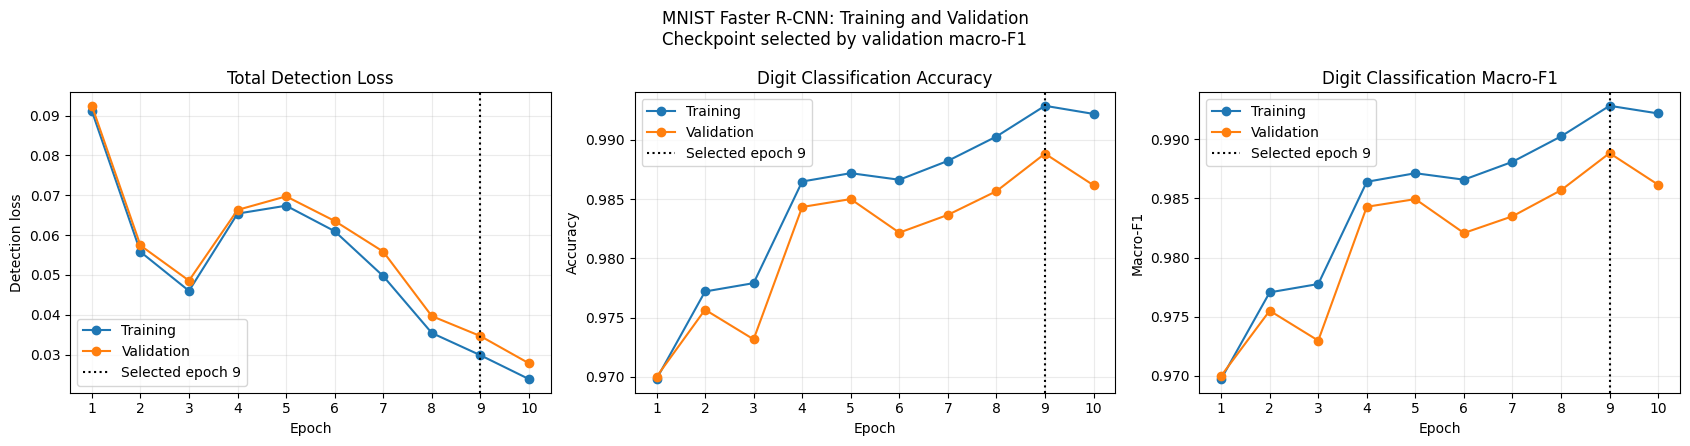

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

plot_settings = [
    ("loss", "Total Detection Loss", "Detection loss"),
    ("accuracy", "Digit Classification Accuracy", "Accuracy"),
    ("macro_f1", "Digit Classification Macro-F1", "Macro-F1"),
]

for ax, (metric, title, ylabel) in zip(axes, plot_settings):
    ax.plot(
        faster_rcnn_history_df["epoch"],
        faster_rcnn_history_df[f"train_{metric}"],
        marker="o",
        label="Training",
    )
    ax.plot(
        faster_rcnn_history_df["epoch"],
        faster_rcnn_history_df[f"validation_{metric}"],
        marker="o",
        label="Validation",
    )
    ax.axvline(
        faster_rcnn_best_epoch,
        color="black",
        linestyle=":",
        label=f"Selected epoch {faster_rcnn_best_epoch}",
    )
    ax.set(
        title=title,
        xlabel="Epoch",
        ylabel=ylabel,
        xticks=faster_rcnn_history_df["epoch"],
    )
    ax.grid(alpha=0.25)
    ax.legend()

fig.suptitle(
    "MNIST Faster R-CNN: Training and Validation\n"
    "Checkpoint selected by validation macro-F1"
)
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "faster_rcnn_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

,precision,recall,f1-score,support
0,0.9883,0.9983,0.9933,592.0
1,0.9911,0.9955,0.9933,674.0
2,0.9737,0.9950,0.9842,596.0
3,0.9967,0.9804,0.9885,613.0
4,0.9847,0.9932,0.9889,584.0
5,0.9981,0.9871,0.9926,542.0
6,0.9966,0.9932,0.9949,592.0
7,0.9841,0.9856,0.9849,627.0
8,0.9847,0.9880,0.9863,585.0
9,0.9914,0.9714,0.9813,595.0


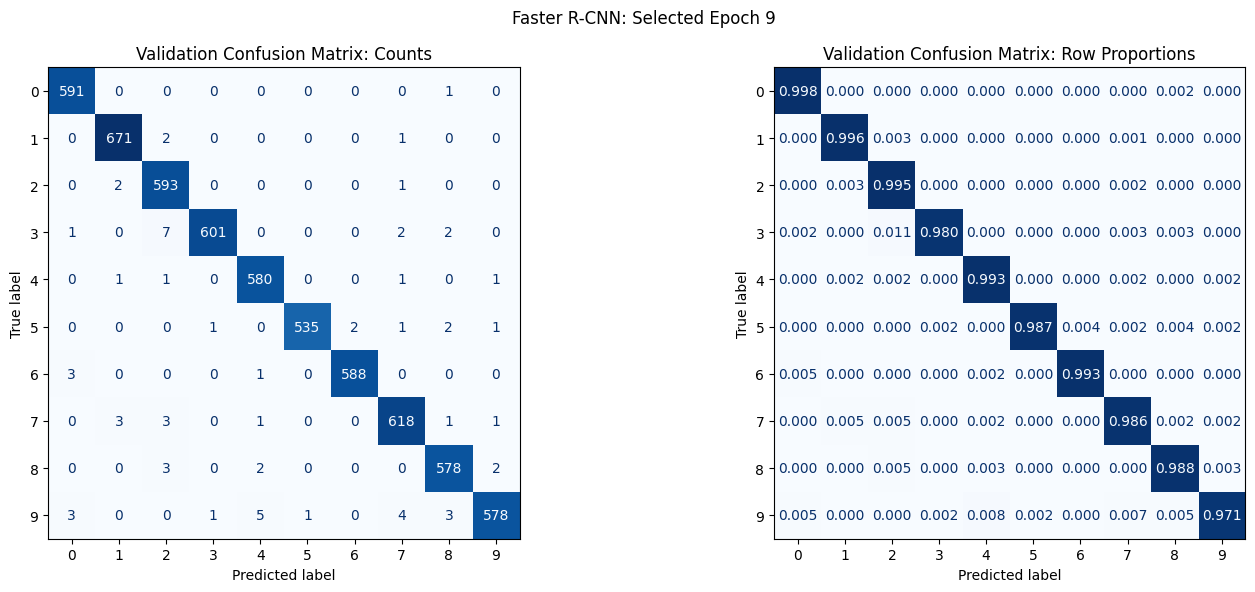

PASS: classification report matches verified validation macro-F1.
Test set remains unevaluated.


In [25]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

assert (faster_rcnn_val_pred >= 0).all()

faster_rcnn_report = classification_report(
    faster_rcnn_val_true,
    faster_rcnn_val_pred,
    labels=np.arange(10),
    target_names=[str(digit) for digit in range(10)],
    output_dict=True,
    zero_division=0,
)

faster_rcnn_class_report = pd.DataFrame(faster_rcnn_report).T.loc[
    [str(digit) for digit in range(10)] + ["macro avg", "weighted avg"]
]

display(faster_rcnn_class_report.round(4))

faster_rcnn_class_report.to_csv(
    RESULTS_DIR / "faster_rcnn_validation_classification_report.csv",
    index_label="class_or_summary",
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for ax, normalization, title, value_format in [
    (axes[0], None, "Validation Confusion Matrix: Counts", "d"),
    (axes[1], "true", "Validation Confusion Matrix: Row Proportions", ".3f"),
]:
    ConfusionMatrixDisplay.from_predictions(
        faster_rcnn_val_true,
        faster_rcnn_val_pred,
        labels=np.arange(10),
        normalize=normalization,
        cmap="Blues",
        values_format=value_format,
        ax=ax,
        colorbar=False,
    )
    ax.set_title(title)

fig.suptitle(
    f"Faster R-CNN: Selected Epoch {faster_rcnn_best_epoch}"
)
fig.tight_layout()
fig.savefig(
    PLOTS_DIR / "faster_rcnn_validation_confusion.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

assert np.isclose(
    faster_rcnn_report["macro avg"]["f1-score"],
    verified_metrics["macro_f1"],
)

print("PASS: classification report matches verified validation macro-F1.")
print("Test set remains unevaluated.")

In [26]:
faster_rcnn_metrics_df = pd.DataFrame([
    {
        "model": "Faster R-CNN",
        "split": split,
        "selected_epoch": faster_rcnn_best_epoch,
        **faster_rcnn_checkpoint[key],
    }
    for split, key in [
        ("train", "training_metrics"),
        ("validation", "validation_metrics"),
    ]
])

faster_rcnn_metrics_df.to_csv(
    RESULTS_DIR / "faster_rcnn_metrics.csv",
    index=False,
)

assert best_checkpoint_path.is_file()
assert best_checkpoint_path.stat().st_size > 0
assert len(faster_rcnn_predictions_df) == 6000
assert int(
    (faster_rcnn_val_true != faster_rcnn_val_pred).sum()
) == 67

display(faster_rcnn_metrics_df.round(6))

print("Selected epoch:", faster_rcnn_best_epoch)
print("Checkpoint:", best_checkpoint_path)
print("Checkpoint size:", best_checkpoint_path.stat().st_size, "bytes")
print("PASS: selected metrics saved and checkpoint available.")
print("Test set remains unevaluated.")

,model,split,selected_epoch,loss,loss_classifier,loss_box_reg,loss_objectness,loss_rpn_box_reg,accuracy,macro_f1,missing_detections
0,Faster R-CNN,train,9,0.029883,0.016503,0.013335,0.0,0.000045,0.992870,0.992830,0
1,Faster R-CNN,validation,9,0.034690,0.021106,0.013537,0.0,0.000047,0.988833,0.988829,0


Selected epoch: 9
Checkpoint: /kaggle/working/checkpoints/faster_rcnn_best.pt
Checkpoint size: 1945925 bytes
PASS: selected metrics saved and checkpoint available.
Test set remains unevaluated.


### Faster R-CNN results and interpretation

A full Faster R-CNN detector was trained from scratch using a small custom
CNN backbone, with 484,388 trainable parameters. Each MNIST image was
represented as one object with a derived full-image bounding box.
These boxes support the classification adaptation; they do not demonstrate
real-world object localization performance.

Training ran for 10 epochs on two Tesla T4 GPUs using DistributedDataParallel,
with a global batch size of 32. The run took 57.20 minutes, including full
training and validation evaluations and checkpoint saving.

Epoch 9 was selected by validation macro-F1. It achieved 98.88% validation
accuracy and 0.9888 macro-F1, with 67 errors among 6,000 images and no missing
detections. Digit 9 had the lowest recall, followed by digit 3.

Epoch 10 had lower detection loss but lower validation macro-F1.
This is possible because detection loss combines classification and
localization objectives. It is not directly comparable to the CNN's
cross-entropy loss.

The selected checkpoint was restored and its validation predictions were
independently verified. The test set remains unevaluated.

## 6. CNN versus Faster R-CNN

We compare both models on the same 6,000 validation images using accuracy,
macro-F1, loss, and measured run time.

CNN loss is cross-entropy; Faster R-CNN loss combines classification and
localization objectives. Their loss values are reported separately and
cannot be ranked directly.

The CNN used one T4 GPU, while Faster R-CNN used two. Run times include
evaluation overhead, so they describe the complete experiments rather
than a controlled hardware benchmark.

The CNN checkpoint was selected by validation loss; Faster R-CNN was
selected by validation macro-F1. The test set remains unevaluated.

In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required_files = [
    "cnn_config.json",
    "cnn_validation_predictions.csv",
    "faster_rcnn_run_config.json",
    "faster_rcnn_metrics.csv",
    "faster_rcnn_validation_predictions.csv",
]

comparison_paths = {}

for filename in required_files:
    matches = sorted(Path("/kaggle/input").rglob(filename))

    assert len(matches) == 1, (
        f"Expected one copy of {filename}, found {len(matches)}: {matches}"
    )

    comparison_paths[filename] = matches[0]
    print(f"{filename}: {matches[0]}")

cnn_comparison_config = json.loads(
    comparison_paths["cnn_config.json"].read_text()
)
rcnn_comparison_config = json.loads(
    comparison_paths["faster_rcnn_run_config.json"].read_text()
)

cnn_comparison_predictions = pd.read_csv(
    comparison_paths["cnn_validation_predictions.csv"]
)
rcnn_comparison_predictions = pd.read_csv(
    comparison_paths["faster_rcnn_validation_predictions.csv"]
)
rcnn_comparison_metrics = pd.read_csv(
    comparison_paths["faster_rcnn_metrics.csv"]
)

assert (
    cnn_comparison_config["split_sha256"]
    == rcnn_comparison_config["split_sha256"]
)
assert (
    cnn_comparison_config["source_sha256"]
    == rcnn_comparison_config["source_sha256"]
)

print("\nCNN prediction rows:", len(cnn_comparison_predictions))
print("Faster R-CNN prediction rows:", len(rcnn_comparison_predictions))
print("Shared split SHA256:", cnn_comparison_config["split_sha256"])
print("PASS: files loaded; source and split hashes match.")
print("No training or test evaluation performed.")

cnn_config.json: /kaggle/input/datasets/soulaimanebenayad/results/cnn_config.json
cnn_validation_predictions.csv: /kaggle/input/datasets/soulaimanebenayad/results/cnn_validation_predictions.csv
faster_rcnn_run_config.json: /kaggle/input/datasets/soulaimanebenayad/results/faster_rcnn_run_config.json
faster_rcnn_metrics.csv: /kaggle/input/datasets/soulaimanebenayad/results/faster_rcnn_metrics.csv
faster_rcnn_validation_predictions.csv: /kaggle/input/datasets/soulaimanebenayad/results/faster_rcnn_validation_predictions.csv

CNN prediction rows: 6000
Faster R-CNN prediction rows: 6000
Shared split SHA256: d42d6480e8042889f5d4e6ae98011dc1f7014582fc33baf093d8a5d847f395f4
PASS: files loaded; source and split hashes match.
No training or test evaluation performed.


In [2]:
from sklearn.metrics import accuracy_score, f1_score

required_columns = ["source_index", "true_digit", "predicted_digit"]

for name, frame in [
    ("CNN", cnn_comparison_predictions),
    ("Faster R-CNN", rcnn_comparison_predictions),
]:
    assert set(required_columns).issubset(frame.columns)
    assert len(frame) == 6000
    assert not frame["source_index"].duplicated().any()
    assert not frame[required_columns].isna().any().any()
    assert frame["true_digit"].isin(range(10)).all()
    assert frame["predicted_digit"].isin([-1, *range(10)]).all()

assert set(cnn_comparison_predictions["source_index"]) == set(
    rcnn_comparison_predictions["source_index"]
)

aligned_predictions = cnn_comparison_predictions[
    required_columns
].merge(
    rcnn_comparison_predictions[required_columns],
    on="source_index",
    how="inner",
    suffixes=("_cnn", "_rcnn"),
    validate="one_to_one",
).sort_values("source_index").reset_index(drop=True)

assert len(aligned_predictions) == 6000
assert np.array_equal(
    aligned_predictions["true_digit_cnn"],
    aligned_predictions["true_digit_rcnn"],
)

rcnn_validation_rows = rcnn_comparison_metrics.loc[
    rcnn_comparison_metrics["split"] == "validation"
]
assert len(rcnn_validation_rows) == 1
rcnn_validation_record = rcnn_validation_rows.iloc[0]

verification_rows = []

for name, prediction_column, expected in [
    (
        "CNN",
        "predicted_digit_cnn",
        cnn_comparison_config["validation_metrics"],
    ),
    (
        "Faster R-CNN",
        "predicted_digit_rcnn",
        rcnn_validation_record,
    ),
]:
    y_true = aligned_predictions["true_digit_cnn"]
    y_pred = aligned_predictions[prediction_column]

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(
        y_true,
        y_pred,
        labels=np.arange(10),
        average="macro",
        zero_division=0,
    )

    assert np.isclose(accuracy, float(expected["accuracy"]), atol=1e-10, rtol=0)
    assert np.isclose(macro_f1, float(expected["macro_f1"]), atol=1e-10, rtol=0)

    verification_rows.append({
        "model": name,
        "validation_samples": len(y_true),
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "errors": int((y_true != y_pred).sum()),
        "missing_detections": int((y_pred == -1).sum()),
    })

comparison_verified_metrics = pd.DataFrame(verification_rows)
display(comparison_verified_metrics.round(6))

print("PASS: identical validation image IDs and labels.")
print("PASS: recomputed metrics match both saved experiments.")
print("Test set remains unevaluated.")

,model,validation_samples,accuracy,macro_f1,errors,missing_detections
0,CNN,6000,0.991500,0.991446,51,0
1,Faster R-CNN,6000,0.988833,0.988829,67,0


PASS: identical validation image IDs and labels.
PASS: recomputed metrics match both saved experiments.
Test set remains unevaluated.


In [3]:
RESULTS_DIR = Path("/kaggle/working/results")
PLOTS_DIR = Path("/kaggle/working/plots")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

comparison_details = pd.DataFrame([
    {
        "model": "CNN",
        "selected_epoch": cnn_comparison_config["selected_epoch"],
        "selection_metric": "Minimum validation cross-entropy",
        "validation_loss": cnn_comparison_config["validation_metrics"]["loss"],
        "loss_type": "Cross-entropy",
        "training_seconds": cnn_comparison_config["training_seconds"],
        "gpus_used": cnn_comparison_config["gpus_used"],
    },
    {
        "model": "Faster R-CNN",
        "selected_epoch": rcnn_comparison_config["selected_epoch"],
        "selection_metric": "Maximum validation macro-F1",
        "validation_loss": float(rcnn_validation_record["loss"]),
        "loss_type": "Total detection loss",
        "training_seconds": rcnn_comparison_config["training_seconds"],
        "gpus_used": rcnn_comparison_config["gpus_used"],
    },
])

comparison_table = comparison_verified_metrics.merge(
    comparison_details,
    on="model",
    validate="one_to_one",
)

comparison_table["training_minutes"] = (
    comparison_table["training_seconds"] / 60
)

display(comparison_table[[
    "model",
    "selected_epoch",
    "accuracy",
    "macro_f1",
    "errors",
    "validation_loss",
    "loss_type",
    "training_seconds",
    "training_minutes",
    "gpus_used",
]].round(6))

comparison_table.to_csv(
    RESULTS_DIR / "cnn_vs_faster_rcnn_comparison.csv",
    index=False,
)

comparison_protocol = {
    "partition": "validation",
    "samples": len(aligned_predictions),
    "split_sha256": cnn_comparison_config["split_sha256"],
    "source_sha256": cnn_comparison_config["source_sha256"],
    "cnn_timing_scope": cnn_comparison_config["timing_scope"],
    "faster_rcnn_timing_scope": rcnn_comparison_config["timing_scope"],
    "limitations": [
        "Different checkpoint-selection metrics.",
        "Classification and detection losses are not directly comparable.",
        "Different GPU counts and evaluation workloads.",
        "Full-image boxes adapt MNIST to detection; localization is not assessed.",
        "One run per model; differences do not establish general superiority.",
    ],
    "test_evaluated": False,
}

(RESULTS_DIR / "cnn_vs_faster_rcnn_protocol.json").write_text(
    json.dumps(comparison_protocol, indent=2),
    encoding="utf-8",
)

print("PASS: comparison table and protocol saved.")
print("Loss values must not be ranked across these different objectives.")
print("Run times describe the recorded experiments, not a controlled speed benchmark.")

,model,selected_epoch,accuracy,macro_f1,errors,validation_loss,loss_type,training_seconds,training_minutes,gpus_used
0,CNN,10,0.991500,0.991446,51,0.03526,Cross-entropy,32.100712,0.535012,1
1,Faster R-CNN,9,0.988833,0.988829,67,0.03469,Total detection loss,3432.163973,57.202733,2


PASS: comparison table and protocol saved.
Loss values must not be ranked across these different objectives.
Run times describe the recorded experiments, not a controlled speed benchmark.


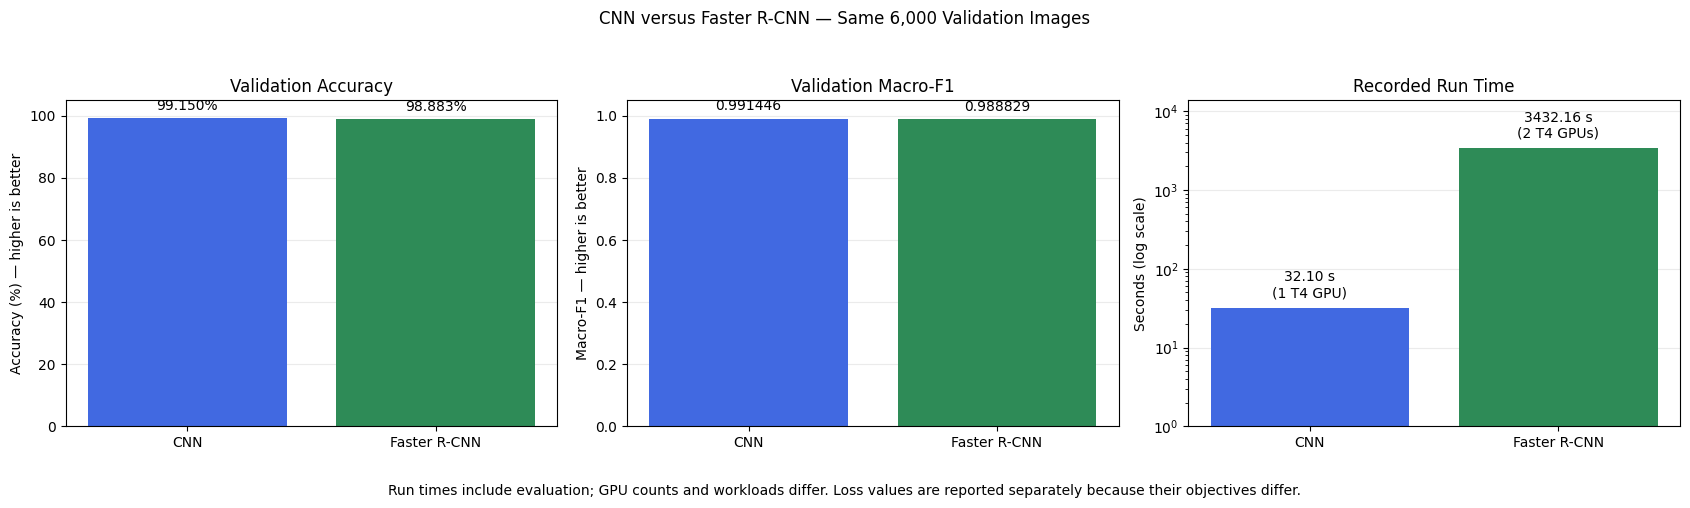

In [4]:
plot_data = comparison_table.set_index("model").loc[
    ["CNN", "Faster R-CNN"]
]

model_names = plot_data.index.tolist()
colors = ["royalblue", "seagreen"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

accuracy_values = plot_data["accuracy"].to_numpy() * 100
bars = axes[0].bar(model_names, accuracy_values, color=colors)
axes[0].bar_label(
    bars,
    labels=[f"{value:.3f}%" for value in accuracy_values],
    padding=4,
)
axes[0].set(
    title="Validation Accuracy",
    ylabel="Accuracy (%) — higher is better",
    ylim=(0, 105),
)

f1_values = plot_data["macro_f1"].to_numpy()
bars = axes[1].bar(model_names, f1_values, color=colors)
axes[1].bar_label(
    bars,
    labels=[f"{value:.6f}" for value in f1_values],
    padding=4,
)
axes[1].set(
    title="Validation Macro-F1",
    ylabel="Macro-F1 — higher is better",
    ylim=(0, 1.05),
)

time_values = plot_data["training_seconds"].to_numpy()
time_labels = [
    f"{seconds:.2f} s\n({int(gpus)} T4 GPU{'s' if gpus > 1 else ''})"
    for seconds, gpus in zip(time_values, plot_data["gpus_used"])
]

axes[2].bar(model_names, time_values, color=colors)
axes[2].set_yscale("log")
axes[2].set(
    title="Recorded Run Time",
    ylabel="Seconds (log scale)",
    ylim=(1, time_values.max() * 4),
)

for index, (seconds, label) in enumerate(zip(time_values, time_labels)):
    axes[2].annotate(
        label,
        (index, seconds),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
    )

for ax in axes:
    ax.set_axisbelow(True)
    ax.grid(axis="y", alpha=0.25)

fig.suptitle(
    "CNN versus Faster R-CNN — Same 6,000 Validation Images"
)
fig.text(
    0.5,
    0.01,
    "Run times include evaluation; GPU counts and workloads differ. "
    "Loss values are reported separately because their objectives differ.",
    ha="center",
    fontsize=10,
)
fig.tight_layout(rect=[0, 0.07, 1, 0.94])

fig.savefig(
    PLOTS_DIR / "cnn_vs_faster_rcnn_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### CNN versus Faster R-CNN: conclusion

On the same 6,000 validation images, the CNN achieved 99.15% accuracy
and 0.991446 macro-F1, compared with 98.8833% accuracy and 0.988829
macro-F1 for Faster R-CNN. The CNN made 51 errors versus 67, giving
16 fewer errors and an accuracy advantage of 0.267 percentage points.

The recorded CNN run took 32.10 seconds on one T4 GPU. Faster R-CNN
took 57.20 minutes on two T4 GPUs. Both durations include evaluation,
but the workloads differ: Faster R-CNN requires separate prediction
and detection-loss passes. These timings describe our experiments,
not a controlled hardware benchmark.

The CNN's validation cross-entropy was 0.035260. Faster R-CNN's total
detection loss was 0.034690. These losses measure different objectives,
so the smaller numerical value does not establish a better model.

For this single-digit MNIST experiment, the CNN provided slightly
better validation classification results with a much shorter recorded
run time. Faster R-CNN adds proposal generation and box regression,
although each image contains only one digit with a full-image box.
This experiment does not assess genuine object localization.

The models used different checkpoint-selection criteria, and only one
run per model was compared. The findings therefore apply to these
configurations and do not establish general superiority. The test set
remains unevaluated.